In [1]:
import gym, warnings, torch, os, gc
import pandas as pd
from tqdm.notebook import tqdm
from models import PolicyNet, SparsePolicyNet
from utils import (
    low_rank_approximate_policy, 
    plot_result_dataframe, 
    run_evaluation
)
warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
os.environ["DEVICE"] = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
env = gym.make("CartPole-v1", render_mode="human")

#model hyper-parameters
observation_space = env.observation_space._shape[0]
action_space = env.action_space.n
hidden_size = 128
ranks = range(10, 30)

# Low Rank Approximation of DQN Policies

## Low Rank Approximation for Dense Policy

#### **Evaluate Dense Policy**

In [3]:
dense_weights_filename = "CartPolev1_DQN_dense_agent.pth.tar"
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.load_state_dict(torch.load(os.path.join("params", dense_weights_filename), map_location=os.getenv("DEVICE")))

run_evaluation(dense_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.4832136
Pole angle variance of policy: 6.73e-05 rads


(500.0, 0.4832136144936085, 6.73293814313575e-05)

#### **Evaluate Low Rank Approximated Dense Policy**

  0%|          | 0/20 [00:00<?, ?it/s]

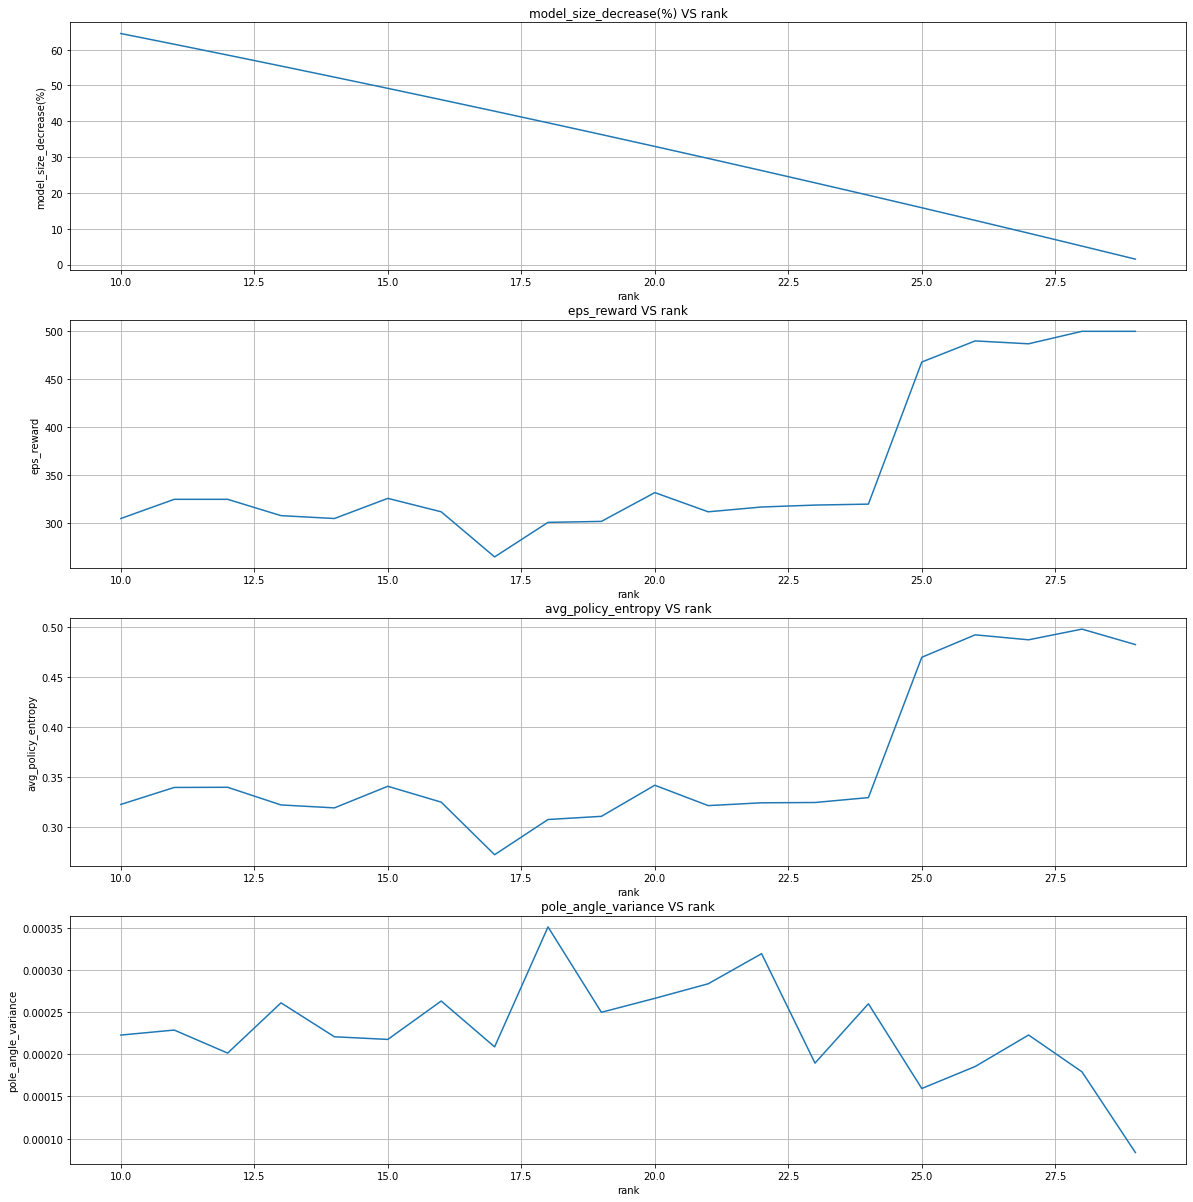

,rank,model_size_decrease(%),eps_reward,avg_policy_entropy,pole_angle_variance
0,10,64.481072,305.0,0.322228,0.000223
1,11,61.492483,325.0,0.339290,0.000229
2,12,58.467669,325.0,0.339453,0.000201
3,13,55.406629,308.0,0.321723,0.000261
4,14,52.309364,305.0,0.318781,0.000221
5,15,49.175874,326.0,0.340473,0.000218
6,16,46.006158,312.0,0.324538,0.000263
7,17,42.800217,265.0,0.271750,0.000209
8,18,39.558051,301.0,0.307101,0.000351
9,19,36.279659,302.0,0.310297,0.000250


In [4]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_dense_policy_agent, p = low_rank_approximate_policy(dense_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_dense_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)
    
result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank")
result

## Low Rank Approximation for Sparse Policy

#### **Evaluate Sparse Policy**

In [5]:
sparse_weights_filename = "CartPolev1_DQN_sparse_agent.pth.tar"
sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
sparse_policy_agent.load_state_dict(torch.load(os.path.join("params", sparse_weights_filename), map_location=os.getenv("DEVICE")))

result_df = run_evaluation(sparse_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6327478
Pole angle variance of policy: 5.93e-05 rads


#### **Evaluate Low Rank Approximated Sparse Policy**

  0%|          | 0/20 [00:00<?, ?it/s]

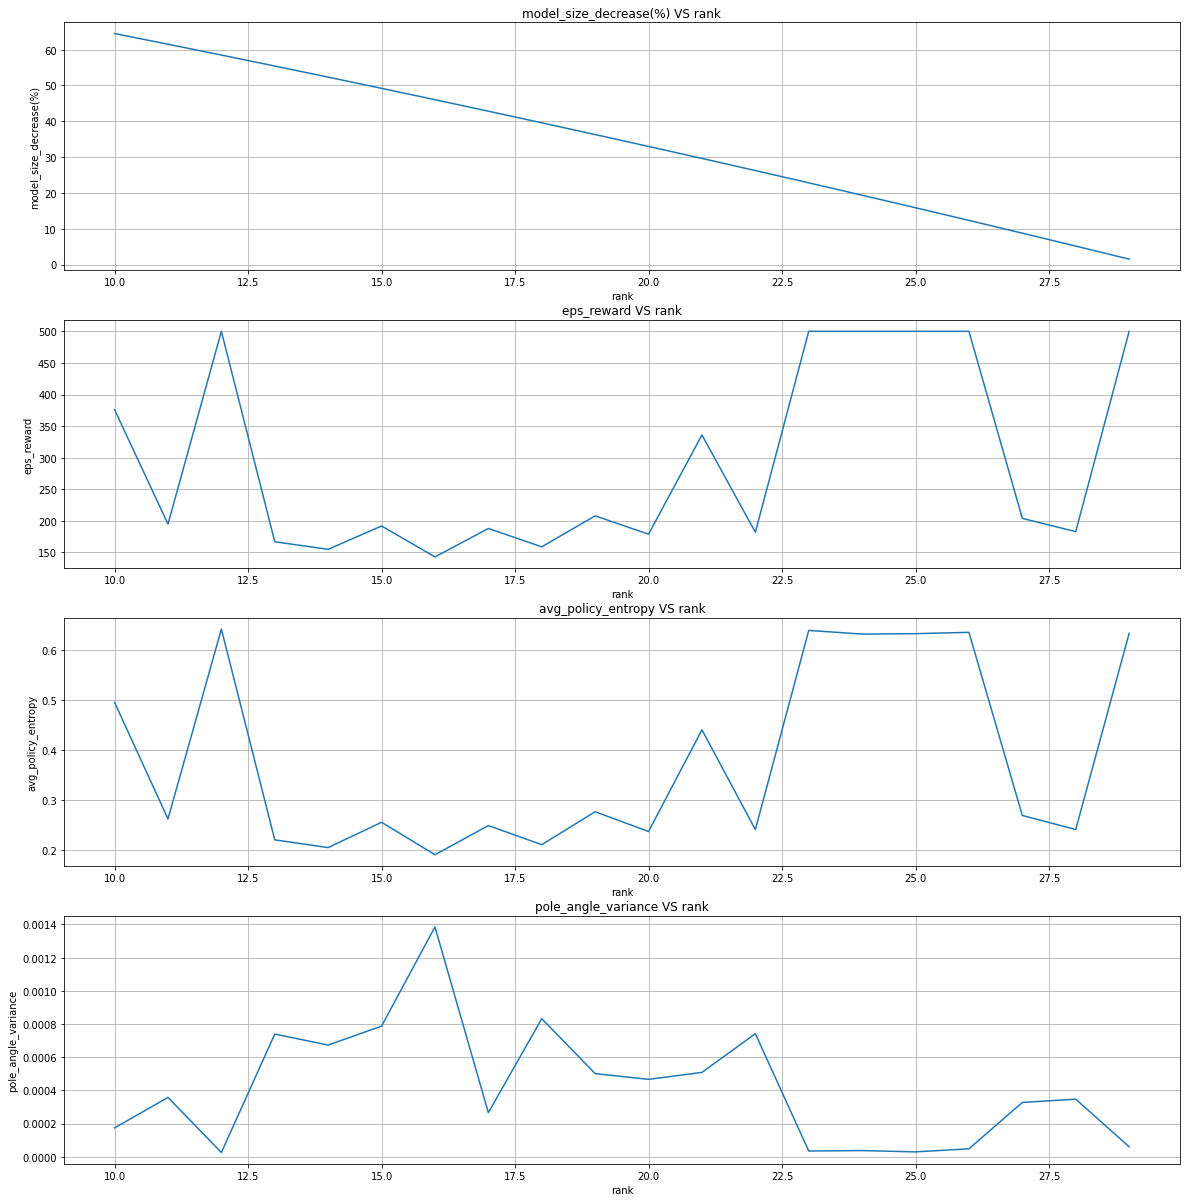

,rank,model_size_decrease(%),eps_reward,avg_policy_entropy,pole_angle_variance
0,10,64.481072,376.0,0.494888,0.000174
1,11,61.492483,195.0,0.262828,0.000357
2,12,58.467669,500.0,0.640930,0.000025
3,13,55.406629,167.0,0.221090,0.000739
4,14,52.309364,155.0,0.205697,0.000673
5,15,49.175874,192.0,0.256114,0.000787
6,16,46.006158,143.0,0.191480,0.001385
7,17,42.800217,188.0,0.249562,0.000266
8,18,39.558051,159.0,0.211473,0.000832
9,19,36.279659,208.0,0.277140,0.000501


In [6]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_sparse_policy_agent, p = low_rank_approximate_policy(sparse_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_sparse_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank")
result

In [7]:
del dense_policy_agent, sparse_policy_agent, lra_dense_policy_agent, lra_sparse_policy_agent, result
gc.collect()
torch.cuda.empty_cache()

# Low Rank Approximation of PPO Policies

#### **Evaluate Dense Policy**

In [8]:
dense_weights_filename = "CartPolev1_PPO_dense_policy_agent.pth.tar"
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.load_state_dict(torch.load(os.path.join("params", dense_weights_filename), map_location=os.getenv("DEVICE")))

run_evaluation(dense_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6115037
Pole angle variance of policy: 2.31e-05 rads


(500.0, 0.6115036581158638, 2.3060248372842353e-05)

#### **Evaluate Low Rank Approximated Dense Policy**

  0%|          | 0/20 [00:00<?, ?it/s]

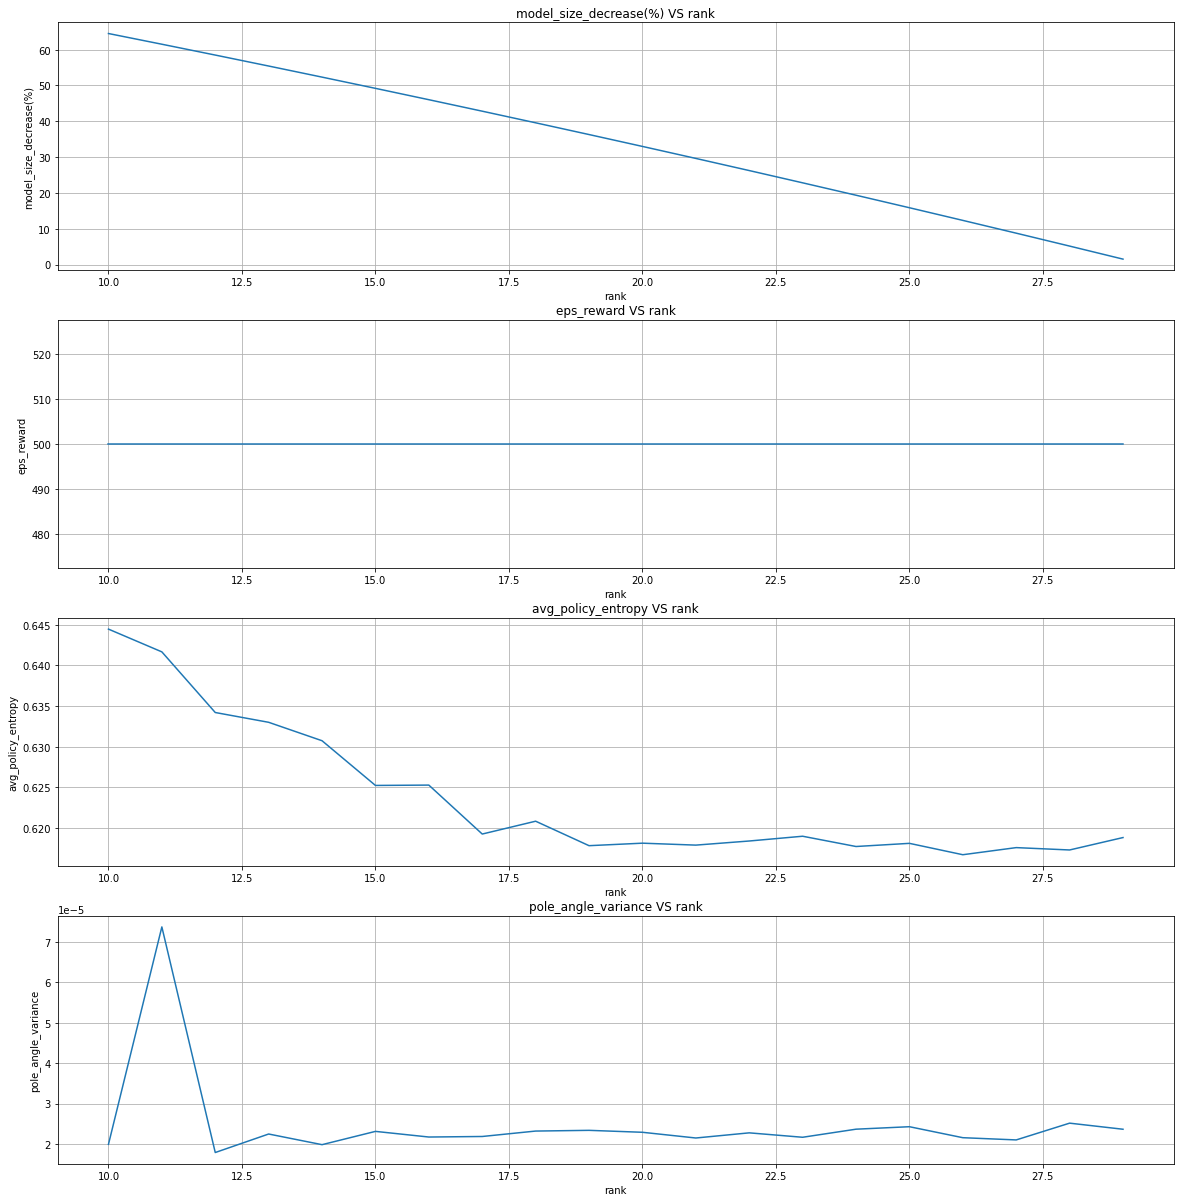

,rank,model_size_decrease(%),eps_reward,avg_policy_entropy,pole_angle_variance
0,10,64.481072,500.0,0.644447,0.000020
1,11,61.492483,500.0,0.641649,0.000074
2,12,58.467669,500.0,0.634195,0.000018
3,13,55.406629,500.0,0.632991,0.000022
4,14,52.309364,500.0,0.630724,0.000020
5,15,49.175874,500.0,0.625229,0.000023
6,16,46.006158,500.0,0.625271,0.000022
7,17,42.800217,500.0,0.619253,0.000022
8,18,39.558051,500.0,0.620831,0.000023
9,19,36.279659,500.0,0.617823,0.000023


In [9]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_dense_policy_agent, p = low_rank_approximate_policy(dense_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_dense_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)
    
result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank")
result

#### **Evaluate Sparse Policy**

In [11]:
sparse_weights_filename = "CartPolev1_PPO_sparse_policy_agent.pth.tar"
sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
sparse_policy_agent.load_state_dict(torch.load(os.path.join("params", sparse_weights_filename), map_location=os.getenv("DEVICE")))

result_df = run_evaluation(sparse_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6228877
Pole angle variance of policy: 2.95e-05 rads


#### **Evaluate Low Rank Approximated Sparse Policy**

  0%|          | 0/20 [00:00<?, ?it/s]

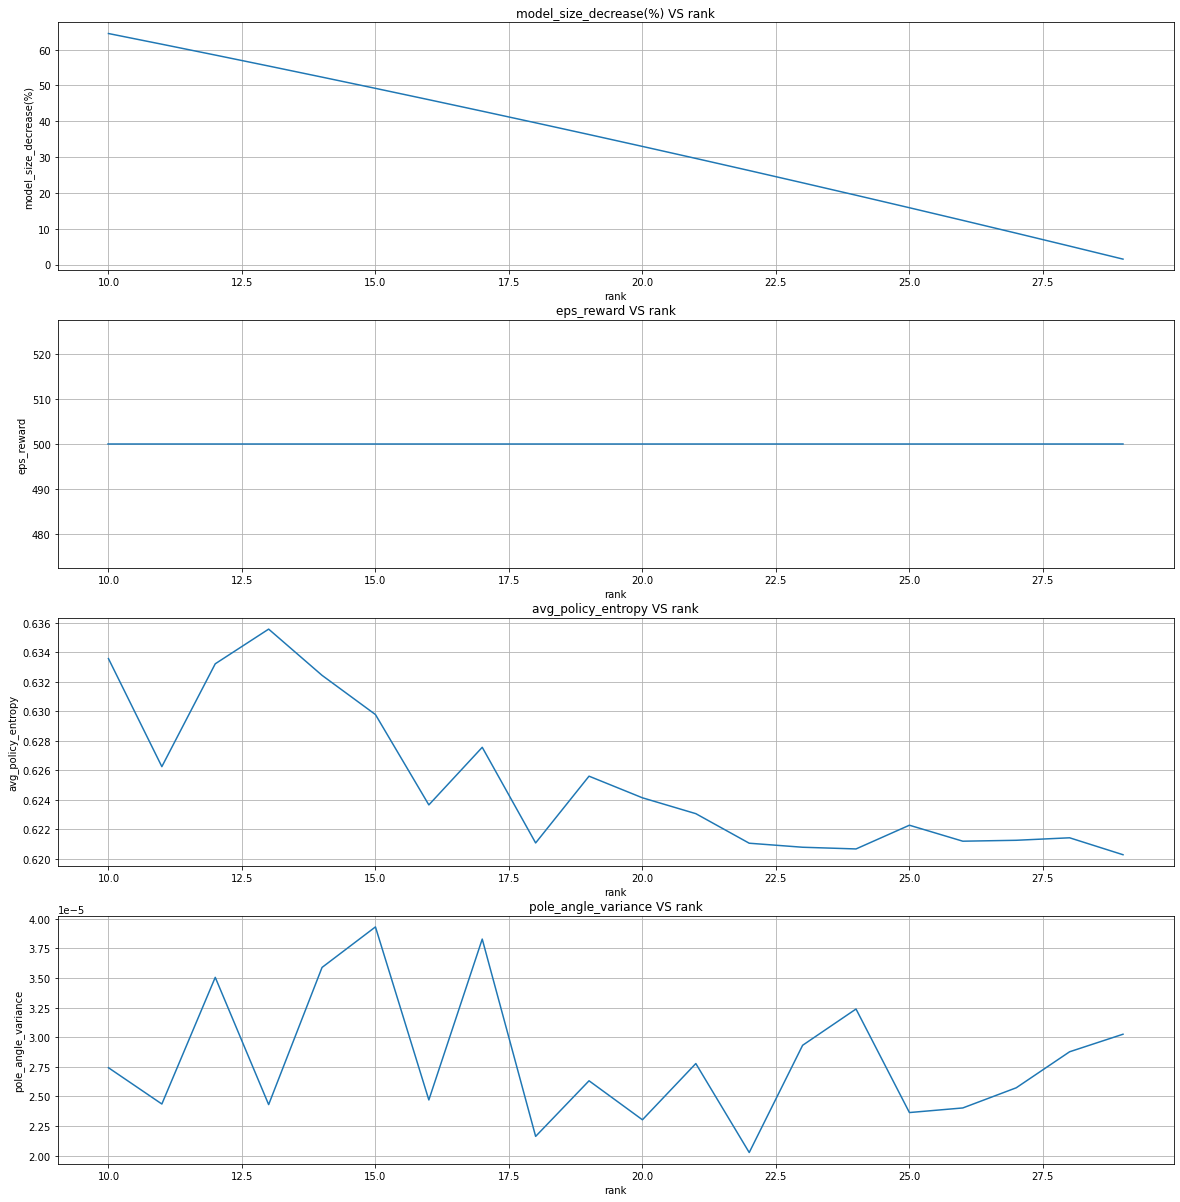

,rank,model_size_decrease(%),eps_reward,avg_policy_entropy,pole_angle_variance
0,10,64.481072,500.0,0.633573,0.000027
1,11,61.492483,500.0,0.626247,0.000024
2,12,58.467669,500.0,0.633221,0.000035
3,13,55.406629,500.0,0.635573,0.000024
4,14,52.309364,500.0,0.632437,0.000036
5,15,49.175874,500.0,0.629779,0.000039
6,16,46.006158,500.0,0.623652,0.000025
7,17,42.800217,500.0,0.627558,0.000038
8,18,39.558051,500.0,0.621072,0.000022
9,19,36.279659,500.0,0.625600,0.000026


In [12]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_sparse_policy_agent, p = low_rank_approximate_policy(sparse_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_sparse_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank")
result

In [13]:
del dense_policy_agent, sparse_policy_agent, lra_dense_policy_agent, lra_sparse_policy_agent, result
gc.collect()
torch.cuda.empty_cache()